In [1]:
%load_ext autoreload
%autoreload 2

# Load hardware data

# Device selection

In [2]:
from cobos.tokens import ibm_token, group_instance, group_instance2
from qiskit_ibm_runtime import QiskitRuntimeService

channel = "ibm_quantum"
# device = "ibm_fez"
# device = "ibm_sherbrooke"
# device = "ibm_torino"
# device = "ibm_marrakesh"
device = "ibm_aachen"
# device = "ibm_kingston"

service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)
backend = service.backend(device)

# Auxiliary lattice plot

72 possible layouts


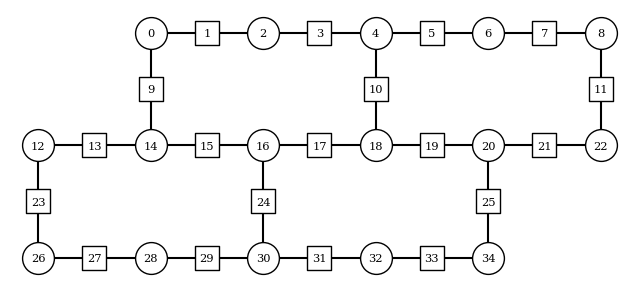

In [3]:
from z2hex.geometry import HeavyHexLattice

plaquette_width = 2
plaquette_height = 2

lattice = HeavyHexLattice(plaquette_width, plaquette_height)
nlayouts = len(lattice.get_all_layouts(backend))
print(f"{nlayouts} possible layouts")
lattice.plot_lattice(number_qubits=True)

# Simulation settings

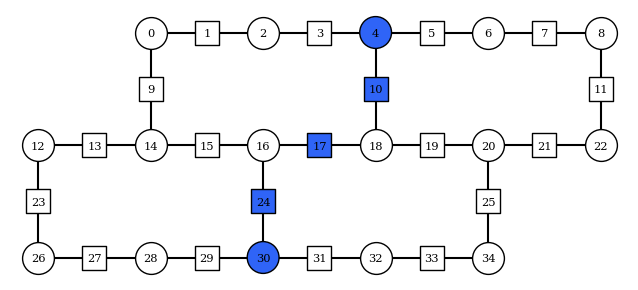

In [4]:
from z2hex.gdd import zero_mean
from utils.hexec import create_estimator_options
from utils.execrecord import ExecutionRecord
from utils.hexec import ExecDB
from functools import partial

lattice_dims = (plaquette_width, plaquette_height)
J = 5
h = 2
lamb = 1

x_basis = False

fractional_gates = False

# string = [27, 26, 34, 43, 52, 60, 71, 78]
# string = [21, 33, 41, 52, 62, 72, 83, 91, 103]
# string = [0, 1, 3, 6, 11]
string = [4, 10, 17, 24, 30]

final_times = [2, 2.5, 3, 3.5, 4]
dts = [0.1, 0.125, 0.15, 0.175, 0.2]
steps = 20
desired_error = 1e-2

max_layers = 50
adjust_depth = True

shots = 75000
confidence = 0.9

odr = True
postselect_odr = True
flip_threshold = 2
all_or_first_layout_qubit = None
forbidden_qubits = []
max_layouts = 4
recovery = True
# g_func = None
# g_func = partial(counteract_rotation, ham_param=J)
# g_func = partial(constant, angle=np.pi)
# g_func = random
g_func = zero_mean

sampler_options = {
    "default_shots": shots,
    "execution": {
        "init_qubits": True,
        "meas_type": "classified"
    },
    "dynamical_decoupling": {
        "enable": True,
        "sequence_type": "XY4"
    },
    "twirling": {
        "enable_gates": True,
        "enable_measure": True,
        "num_randomizations": "auto",
        "shots_per_randomization": "auto"
    },
    "experimental": {
        "execution_path": "gen3-turbo"
    }
}

execution_database = "z2_hex_jobs.json"
jobs_result_folder = execution_database.split(".")[0] + "/"
job_db = ExecDB(execution_database)

circ_folder_path = "Circuits/"

execution_record_path = "../../../../Executions_record.xlsx"
execrecord = ExecutionRecord(execution_record_path)

curated_data_folder_path = "Curated data/"

lattice.plot_highlighted_qubits(string, colors=["#2f64f7"]*len(string), number_qubits=True)

## Load jobs

In [5]:
import pickle
import os

hardware_datas = [] # [(hardware_observables, hardware_observables_confidence, samples_dicts, postselected_samples_dicts, layouts)]

for final_time, dt in zip(final_times, dts):
    data_filepath = os.path.join(curated_data_folder_path, f"z2hexquench_curated_data_{device}_px_{lattice_dims[0]}_py_{lattice_dims[1]}_maxt_{final_time}_dt_{dt}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else g_func}_shots_{shots}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}_dd_{sampler_options["dynamical_decoupling"]["enable"]}_pt_{sampler_options["twirling"]["enable_gates"]}_ft_{flip_threshold}_pODR_{postselect_odr}_confidence_{confidence}.pkl")
    with open(data_filepath, "rb") as f:
        hardware_datas.append(pickle.load(f))

# Load TN data

In [6]:
import numpy as np
import os

tn_dt = 0.01
tn_final_time = 16
tn_exp_order = 30
tn_bond_dimension = 128
tn_data_folderpath = "TN Data/"
tn_data_limits = [int(final_time / tn_dt) for final_time in final_times]

tn_data_filepath = os.path.join(tn_data_folderpath, f"converted_data_BUG_g{h:.02f}_m{J:.02f}_ROWS2_COLS2_dt{tn_dt:.03f}_Tmax{tn_final_time:.02f}_exp_order{tn_exp_order}_M{tn_bond_dimension:05d}.txt")
tn_observables = np.loadtxt(tn_data_filepath)

# Plots

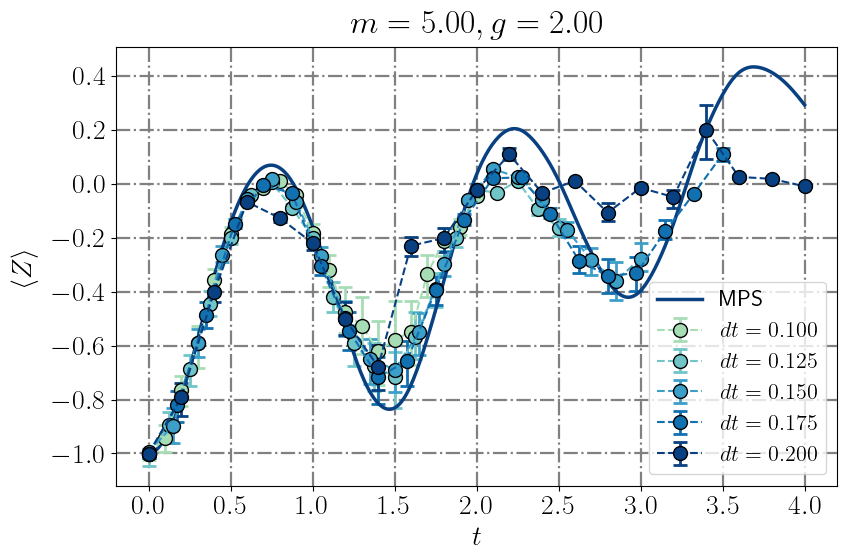

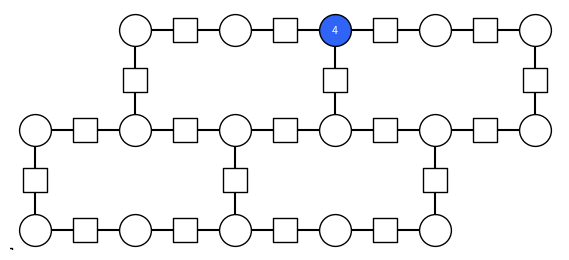

In [14]:
import matplotlib.pyplot as plt

qubit = 4

cmap = lambda x: plt.get_cmap("GnBu")((1.25*(x)+3)/8)
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}$"
legend = True
x_ticks = np.round(np.linspace(0, final_time, 6))
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = None
legend_fontsize = 16

funclabels = [rf"$dt = {dt:.03f}$" for dt in dts] + [r"MPS"]

plot_filepath = f"z2hex_quench_qubits_dtcomp_qb_{qubit}_nODR_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_dtcomp_qb_{qubit}_nODR_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = np.full((steps+1, len(hardware_datas)), np.nan)
hardware_observables_confidences_to_plot = np.zeros((steps+1, len(hardware_datas), 2))
for i, hdata in enumerate(hardware_datas):
    hardware_observables_to_plot[:, i] = hdata[0][0][:, qubit]
    hardware_observables_confidences_to_plot[:, i, :] = hdata[1][0][:, qubit]

tn_observable_to_plot = tn_observables[:tn_data_limits[-1], qubit]

xs = [np.linspace(0, final_time, steps+1) for final_time in final_times]

plt.rc("text", usetex=True)
plt.rc("font", size=20, family="serif", weight="bold")
fig, ax = plt.subplots(figsize=[9, 6])
for i in range(hardware_observables_to_plot.shape[1]):
    color = cmap((i % 8))
    y = hardware_observables_to_plot[:, i]
    if hardware_observables_confidences_to_plot is not None:
        upper_error_bound_mask = np.less(y.reshape((len(y), 1)), hardware_observables_confidences_to_plot[:, i, :])
        lower_error_bound_mask = np.greater(y.reshape((len(y), 1)), hardware_observables_confidences_to_plot[:, i, :])
        consistency_mask = ~np.logical_xor(np.sum(upper_error_bound_mask, axis=1) == 0, np.sum(lower_error_bound_mask, axis=1) == 0)
        upper_error = hardware_observables_confidences_to_plot[:, i, 1][consistency_mask] - y[consistency_mask]
        lower_error = y[consistency_mask] - hardware_observables_confidences_to_plot[:, i, 0][consistency_mask]
        yerr = np.zeros_like(upper_error_bound_mask, dtype=float)
        yerr[consistency_mask, 0] = lower_error
        yerr[consistency_mask, 1] = upper_error
        plt.errorbar(xs[i], y, yerr=yerr.T, fmt="--", marker=markers[i] if markers is not None else "o", markersize=10, elinewidth=2, markeredgecolor="black", color=color, label=funclabels[i] if funclabels is not None else f"Qubit {i}", capsize=5, capthick=2)
    else:
        plt.plot(xs[i], y, "--", marker=markers[i] if markers is not None else "o", markersize=10, markeredgecolor="black", color=color, label=funclabels[i] if funclabels is not None else f"Qubit {i}")

x_tn = np.linspace(0, final_times[-1], tn_observable_to_plot.shape[0])
plt.plot(x_tn, tn_observable_to_plot, "-", color=cmap(((i+1) % 8)), label=funclabels[i+1] if funclabels is not None else f"Function", linewidth=2.5)
plt.xlabel(x_label)
plt.ylabel(y_label, labelpad=10)
plt.grid(color="gray", linestyle="dashdot", linewidth=1.6, zorder=0)
if y_lim == "data":
    min_data = np.nanmin(hardware_observables_to_plot)
    max_data = np.nanmax(hardware_observables_to_plot)
    plt.ylim([min_data - 0.05*(max_data - min_data), max_data + 0.05*(max_data - min_data)])
elif y_lim is not None:
    plt.ylim(y_lim)
if title:
    plt.title(title, pad=10)
if legend: plt.legend(loc="best", fontsize=16 if legend_fontsize is None else legend_fontsize)

plt.tight_layout()
if plot_filepath:
    plt.savefig(plot_filepath, dpi=300, facecolor="none")
lattice.plot_highlighted_qubits([qubit], colors=["#2f64f7"], filepath=legend_filepath)

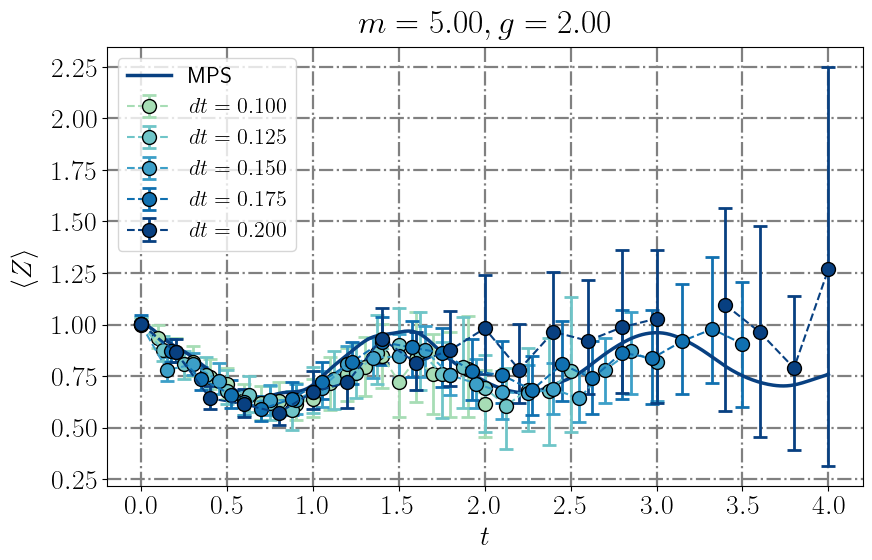

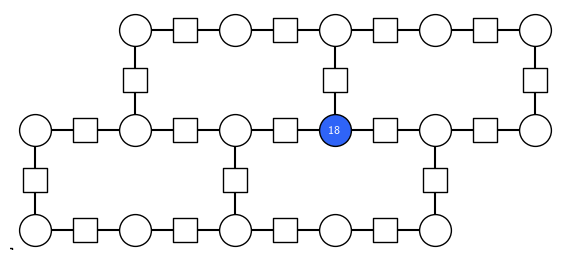

In [18]:
import matplotlib.pyplot as plt

qubit = 18

cmap = lambda x: plt.get_cmap("GnBu")((1.25*(x)+3)/8)
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}$"
legend = True
x_ticks = np.round(np.linspace(0, final_time, 6))
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = None
legend_fontsize = 16

funclabels = [rf"$dt = {dt:.03f}$" for dt in dts] + [r"MPS"]

plot_filepath = f"z2hex_quench_qubits_dtcomp_qb_{qubit}_nODR_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_dtcomp_qb_{qubit}_nODR_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = np.full((steps+1, len(hardware_datas)), np.nan)
hardware_observables_confidences_to_plot = np.zeros((steps+1, len(hardware_datas), 2))
for i, hdata in enumerate(hardware_datas):
    hardware_observables_to_plot[:, i] = hdata[0][0][:, qubit]
    hardware_observables_confidences_to_plot[:, i, :] = hdata[1][0][:, qubit]

tn_observable_to_plot = tn_observables[:tn_data_limits[-1], qubit]

xs = [np.linspace(0, final_time, steps+1) for final_time in final_times]

plt.rc("text", usetex=True)
plt.rc("font", size=20, family="serif", weight="bold")
fig, ax = plt.subplots(figsize=[9, 6])
for i in range(hardware_observables_to_plot.shape[1]):
    color = cmap((i % 8))
    y = hardware_observables_to_plot[:, i]
    if hardware_observables_confidences_to_plot is not None:
        upper_error_bound_mask = np.less(y.reshape((len(y), 1)), hardware_observables_confidences_to_plot[:, i, :])
        lower_error_bound_mask = np.greater(y.reshape((len(y), 1)), hardware_observables_confidences_to_plot[:, i, :])
        consistency_mask = ~np.logical_xor(np.sum(upper_error_bound_mask, axis=1) == 0, np.sum(lower_error_bound_mask, axis=1) == 0)
        upper_error = hardware_observables_confidences_to_plot[:, i, 1][consistency_mask] - y[consistency_mask]
        lower_error = y[consistency_mask] - hardware_observables_confidences_to_plot[:, i, 0][consistency_mask]
        yerr = np.zeros_like(upper_error_bound_mask, dtype=float)
        yerr[consistency_mask, 0] = lower_error
        yerr[consistency_mask, 1] = upper_error
        plt.errorbar(xs[i], y, yerr=yerr.T, fmt="--", marker=markers[i] if markers is not None else "o", markersize=10, elinewidth=2, markeredgecolor="black", color=color, label=funclabels[i] if funclabels is not None else f"Qubit {i}", capsize=5, capthick=2)
    else:
        plt.plot(xs[i], y, "--", marker=markers[i] if markers is not None else "o", markersize=10, markeredgecolor="black", color=color, label=funclabels[i] if funclabels is not None else f"Qubit {i}")

x_tn = np.linspace(0, final_times[-1], tn_observable_to_plot.shape[0])
plt.plot(x_tn, tn_observable_to_plot, "-", color=cmap(((i+1) % 8)), label=funclabels[i+1] if funclabels is not None else f"Function", linewidth=2.5)
plt.xlabel(x_label)
plt.ylabel(y_label, labelpad=10)
plt.grid(color="gray", linestyle="dashdot", linewidth=1.6, zorder=0)
if y_lim == "data":
    min_data = np.nanmin(hardware_observables_to_plot)
    max_data = np.nanmax(hardware_observables_to_plot)
    plt.ylim([min_data - 0.05*(max_data - min_data), max_data + 0.05*(max_data - min_data)])
elif y_lim is not None:
    plt.ylim(y_lim)
if title:
    plt.title(title, pad=10)
if legend: plt.legend(loc="best", fontsize=16 if legend_fontsize is None else legend_fontsize)

plt.tight_layout()
if plot_filepath:
    plt.savefig(plot_filepath, dpi=300, facecolor="none")
lattice.plot_highlighted_qubits([qubit], colors=["#2f64f7"], filepath=legend_filepath)

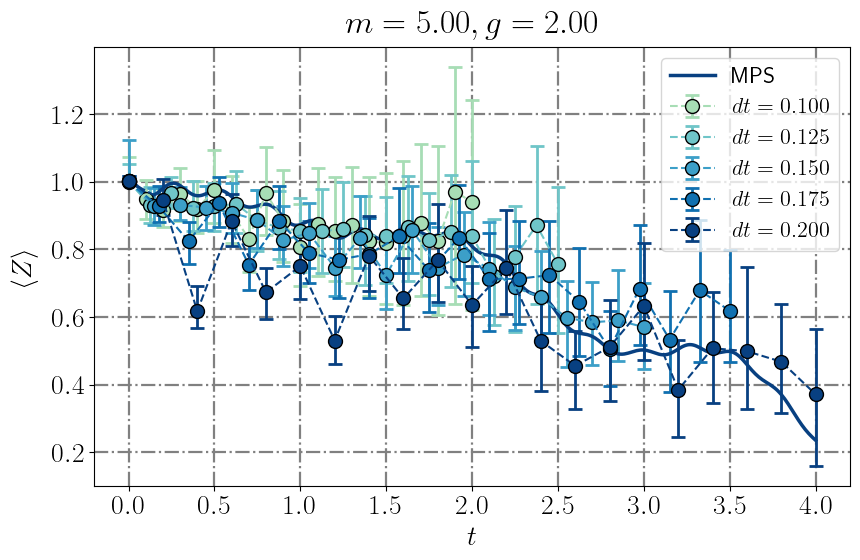

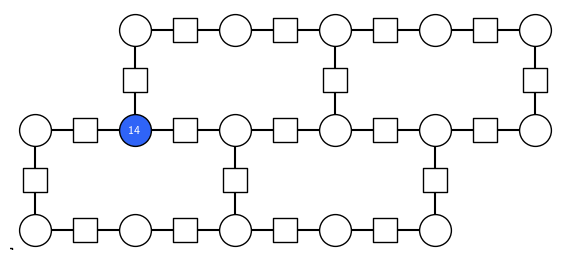

In [15]:
import matplotlib.pyplot as plt

qubit = 14

cmap = lambda x: plt.get_cmap("GnBu")((1.25*(x)+3)/8)
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}$"
legend = True
x_ticks = np.round(np.linspace(0, final_time, 6))
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = None
legend_fontsize = 16

funclabels = [rf"$dt = {dt:.03f}$" for dt in dts] + [r"MPS"]

plot_filepath = f"z2hex_quench_qubits_dtcomp_qb_{qubit}_nODR_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_dtcomp_qb_{qubit}_nODR_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = np.full((steps+1, len(hardware_datas)), np.nan)
hardware_observables_confidences_to_plot = np.zeros((steps+1, len(hardware_datas), 2))
for i, hdata in enumerate(hardware_datas):
    hardware_observables_to_plot[:, i] = hdata[0][0][:, qubit]
    hardware_observables_confidences_to_plot[:, i, :] = hdata[1][0][:, qubit]

tn_observable_to_plot = tn_observables[:tn_data_limits[-1], qubit]

xs = [np.linspace(0, final_time, steps+1) for final_time in final_times]

plt.rc("text", usetex=True)
plt.rc("font", size=20, family="serif", weight="bold")
fig, ax = plt.subplots(figsize=[9, 6])
for i in range(hardware_observables_to_plot.shape[1]):
    color = cmap((i % 8))
    y = hardware_observables_to_plot[:, i]
    if hardware_observables_confidences_to_plot is not None:
        upper_error_bound_mask = np.less(y.reshape((len(y), 1)), hardware_observables_confidences_to_plot[:, i, :])
        lower_error_bound_mask = np.greater(y.reshape((len(y), 1)), hardware_observables_confidences_to_plot[:, i, :])
        consistency_mask = ~np.logical_xor(np.sum(upper_error_bound_mask, axis=1) == 0, np.sum(lower_error_bound_mask, axis=1) == 0)
        upper_error = hardware_observables_confidences_to_plot[:, i, 1][consistency_mask] - y[consistency_mask]
        lower_error = y[consistency_mask] - hardware_observables_confidences_to_plot[:, i, 0][consistency_mask]
        yerr = np.zeros_like(upper_error_bound_mask, dtype=float)
        yerr[consistency_mask, 0] = lower_error
        yerr[consistency_mask, 1] = upper_error
        plt.errorbar(xs[i], y, yerr=yerr.T, fmt="--", marker=markers[i] if markers is not None else "o", markersize=10, elinewidth=2, markeredgecolor="black", color=color, label=funclabels[i] if funclabels is not None else f"Qubit {i}", capsize=5, capthick=2)
    else:
        plt.plot(xs[i], y, "--", marker=markers[i] if markers is not None else "o", markersize=10, markeredgecolor="black", color=color, label=funclabels[i] if funclabels is not None else f"Qubit {i}")

x_tn = np.linspace(0, final_times[-1], tn_observable_to_plot.shape[0])
plt.plot(x_tn, tn_observable_to_plot, "-", color=cmap(((i+1) % 8)), label=funclabels[i+1] if funclabels is not None else f"Function", linewidth=2.5)
plt.xlabel(x_label)
plt.ylabel(y_label, labelpad=10)
plt.grid(color="gray", linestyle="dashdot", linewidth=1.6, zorder=0)
if y_lim == "data":
    min_data = np.nanmin(hardware_observables_to_plot)
    max_data = np.nanmax(hardware_observables_to_plot)
    plt.ylim([min_data - 0.05*(max_data - min_data), max_data + 0.05*(max_data - min_data)])
elif y_lim is not None:
    plt.ylim(y_lim)
if title:
    plt.title(title, pad=10)
if legend: plt.legend(loc="best", fontsize=16 if legend_fontsize is None else legend_fontsize)

plt.tight_layout()
if plot_filepath:
    plt.savefig(plot_filepath, dpi=300, facecolor="none")
lattice.plot_highlighted_qubits([qubit], colors=["#2f64f7"], filepath=legend_filepath)

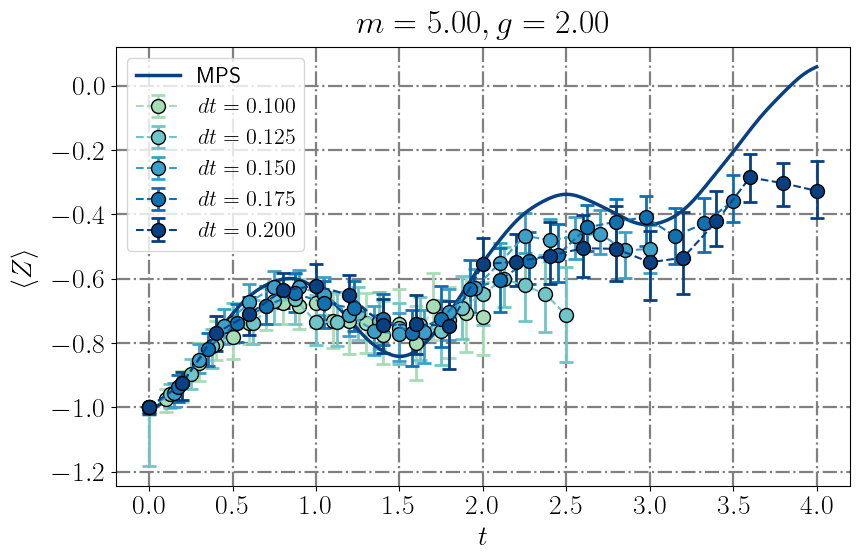

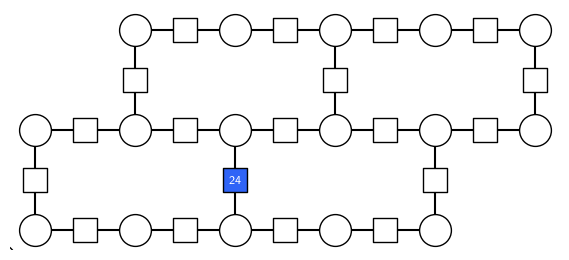

In [17]:
import matplotlib.pyplot as plt

qubit = 24

cmap = lambda x: plt.get_cmap("GnBu")((1.25*(x)+3)/8)
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}$"
legend = True
x_ticks = np.round(np.linspace(0, final_time, 6))
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = None
legend_fontsize = 16

funclabels = [rf"$dt = {dt:.03f}$" for dt in dts] + [r"MPS"]

plot_filepath = f"z2hex_quench_qubits_dtcomp_qb_{qubit}_nODR_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_dtcomp_qb_{qubit}_nODR_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = np.full((steps+1, len(hardware_datas)), np.nan)
hardware_observables_confidences_to_plot = np.zeros((steps+1, len(hardware_datas), 2))
for i, hdata in enumerate(hardware_datas):
    hardware_observables_to_plot[:, i] = hdata[0][0][:, qubit]
    hardware_observables_confidences_to_plot[:, i, :] = hdata[1][0][:, qubit]

tn_observable_to_plot = tn_observables[:tn_data_limits[-1], qubit]

xs = [np.linspace(0, final_time, steps+1) for final_time in final_times]

plt.rc("text", usetex=True)
plt.rc("font", size=20, family="serif", weight="bold")
fig, ax = plt.subplots(figsize=[9, 6])
for i in range(hardware_observables_to_plot.shape[1]):
    color = cmap((i % 8))
    y = hardware_observables_to_plot[:, i]
    if hardware_observables_confidences_to_plot is not None:
        upper_error_bound_mask = np.less(y.reshape((len(y), 1)), hardware_observables_confidences_to_plot[:, i, :])
        lower_error_bound_mask = np.greater(y.reshape((len(y), 1)), hardware_observables_confidences_to_plot[:, i, :])
        consistency_mask = ~np.logical_xor(np.sum(upper_error_bound_mask, axis=1) == 0, np.sum(lower_error_bound_mask, axis=1) == 0)
        upper_error = hardware_observables_confidences_to_plot[:, i, 1][consistency_mask] - y[consistency_mask]
        lower_error = y[consistency_mask] - hardware_observables_confidences_to_plot[:, i, 0][consistency_mask]
        yerr = np.zeros_like(upper_error_bound_mask, dtype=float)
        yerr[consistency_mask, 0] = lower_error
        yerr[consistency_mask, 1] = upper_error
        plt.errorbar(xs[i], y, yerr=yerr.T, fmt="--", marker=markers[i] if markers is not None else "o", markersize=10, elinewidth=2, markeredgecolor="black", color=color, label=funclabels[i] if funclabels is not None else f"Qubit {i}", capsize=5, capthick=2)
    else:
        plt.plot(xs[i], y, "--", marker=markers[i] if markers is not None else "o", markersize=10, markeredgecolor="black", color=color, label=funclabels[i] if funclabels is not None else f"Qubit {i}")

x_tn = np.linspace(0, final_times[-1], tn_observable_to_plot.shape[0])
plt.plot(x_tn, tn_observable_to_plot, "-", color=cmap(((i+1) % 8)), label=funclabels[i+1] if funclabels is not None else f"Function", linewidth=2.5)
plt.xlabel(x_label)
plt.ylabel(y_label, labelpad=10)
plt.grid(color="gray", linestyle="dashdot", linewidth=1.6, zorder=0)
if y_lim == "data":
    min_data = np.nanmin(hardware_observables_to_plot)
    max_data = np.nanmax(hardware_observables_to_plot)
    plt.ylim([min_data - 0.05*(max_data - min_data), max_data + 0.05*(max_data - min_data)])
elif y_lim is not None:
    plt.ylim(y_lim)
if title:
    plt.title(title, pad=10)
if legend: plt.legend(loc="best", fontsize=16 if legend_fontsize is None else legend_fontsize)

plt.tight_layout()
if plot_filepath:
    plt.savefig(plot_filepath, dpi=300, facecolor="none")
lattice.plot_highlighted_qubits([qubit], colors=["#2f64f7"], filepath=legend_filepath)